ML Lab: Principal Component Analysis (PCA)**bold text**

Import Libraries and Load Dataset

In [47]:
# Step 1: Import necessary libraries

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Step 2: Load the Housing dataset

df = pd.read_csv('/content/Housing.csv')

print("Dataset loaded successfully!")
print("\nFirst five rows of the dataset:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully!

First five rows of the dataset:
      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  

Dataset shape: (545, 13)

Column nam

Display Dataset Information

In [48]:
# Step 3: Explore the dataset

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB

Missing Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainro

Convert Categorical Features into Numerical Features

In [49]:
# Step 4: Encode categorical features

housing_encoded = pd.get_dummies(
    df,
    drop_first=True,
    dtype=int
)

print("Dataset after categorical encoding:")
print(housing_encoded.head())

print("\nEncoded dataset shape:", housing_encoded.shape)

Dataset after categorical encoding:
      price  area  bedrooms  bathrooms  stories  parking  mainroad_yes  \
0  13300000  7420         4          2        3        2             1   
1  12250000  8960         4          4        4        3             1   
2  12250000  9960         3          2        2        2             1   
3  12215000  7500         4          2        2        3             1   
4  11410000  7420         4          1        2        2             1   

   guestroom_yes  basement_yes  hotwaterheating_yes  airconditioning_yes  \
0              0             0                    0                    1   
1              0             0                    0                    1   
2              0             1                    0                    0   
3              0             1                    0                    1   
4              1             1                    0                    1   

   prefarea_yes  furnishingstatus_semi-furnished  furnishingst

Standardize the Dataset

In [50]:
# Step 5: Standardize the features

scaler = StandardScaler()

scaled_data = scaler.fit_transform(housing_encoded)

scaled_df = pd.DataFrame(
    scaled_data,
    columns=housing_encoded.columns
)

print("Standardized dataset:")
print(scaled_df.head())

Standardized dataset:
      price      area  bedrooms  bathrooms   stories   parking  mainroad_yes  \
0  4.566365  1.046726  1.403419   1.421812  1.378217  1.517692      0.405623   
1  4.004484  1.757010  1.403419   5.405809  2.532024  2.679409      0.405623   
2  4.004484  2.218232  0.047278   1.421812  0.224410  1.517692      0.405623   
3  3.985755  1.083624  1.403419   1.421812  0.224410  2.679409      0.405623   
4  3.554979  1.046726  1.403419  -0.570187  0.224410  1.517692      0.405623   

   guestroom_yes  basement_yes  hotwaterheating_yes  airconditioning_yes  \
0      -0.465315     -0.734539            -0.219265             1.472618   
1      -0.465315     -0.734539            -0.219265             1.472618   
2      -0.465315      1.361397            -0.219265            -0.679063   
3      -0.465315      1.361397            -0.219265             1.472618   
4       2.149083      1.361397            -0.219265             1.472618   

   prefarea_yes  furnishingstatus_semi-f

Apply Principal Component Analysis

In [51]:
# Step 6: Apply PCA to preserve 90% variance

pca = PCA(n_components=0.90)

reduced_data = pca.fit_transform(scaled_data)

reduced_df = pd.DataFrame(
    reduced_data,
    columns=[f'PC{i+1}' for i in range(reduced_data.shape[1])]
)

print("Dataset after PCA:")
print(reduced_df.head())

print("\nReduced dataset shape:", reduced_df.shape)

Dataset after PCA:
        PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
0  5.073932 -1.787714  0.082783 -0.926486 -0.085566 -0.089575  1.038916   
1  6.452814 -3.106650  1.880144 -0.548599  0.995764  1.767865  0.343934   
2  4.351161  1.245921 -0.556818 -0.867738  0.781507  0.194357  1.899146   
3  5.097084 -0.548516 -1.052190 -0.460499  0.681289  1.115492  1.495113   
4  3.900021 -0.035815 -1.339032  0.612872  0.192965  1.392782 -1.354217   

        PC8       PC9      PC10      PC11  
0  1.114521  0.023629  0.404536  0.597525  
1 -0.956102  1.088880  2.339899  1.069671  
2  0.197352  1.003038  0.863208  0.067860  
3  0.877812 -1.132917  0.848290  0.228703  
4 -0.128496 -0.780843 -1.297180 -0.462608  

Reduced dataset shape: (545, 11)


Display Explained Variance

In [52]:
# Step 7: Calculate explained variance

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nVariance preserved by each component:")

for i, variance in enumerate(pca.explained_variance_ratio_):
    print(f"PC{i+1}: {variance * 100:.2f}%")

total_variance = sum(pca.explained_variance_ratio_) * 100

print("\nTotal Variance Preserved:")
print(f"{total_variance:.2f}%")

Explained Variance Ratio:
[0.22783143 0.11304028 0.10723859 0.09123328 0.07775325 0.06352572
 0.0591129  0.05337763 0.04679177 0.04553534 0.0409538 ]

Variance preserved by each component:
PC1: 22.78%
PC2: 11.30%
PC3: 10.72%
PC4: 9.12%
PC5: 7.78%
PC6: 6.35%
PC7: 5.91%
PC8: 5.34%
PC9: 4.68%
PC10: 4.55%
PC11: 4.10%

Total Variance Preserved:
92.64%


Visualize the PCA Results

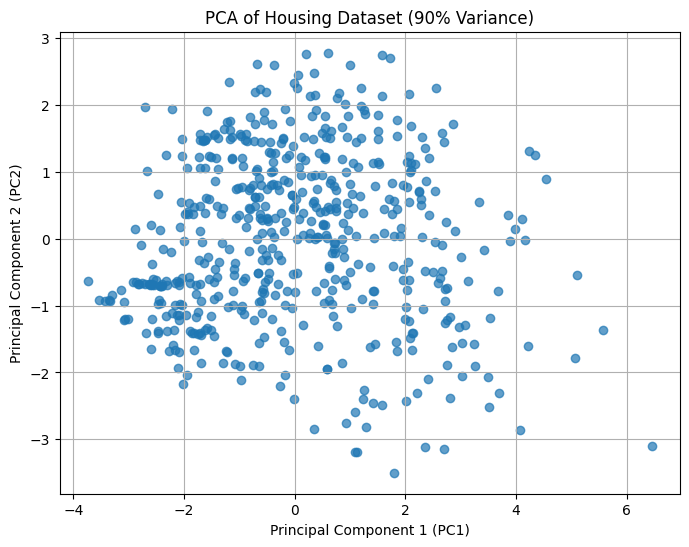

In [53]:
# Step 8: Visualize the reduced dataset

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    reduced_df['PC1'],
    reduced_df['PC2'],
    alpha=0.7
)

plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.title('PCA of Housing Dataset (90% Variance)')
plt.grid(True)

plt.show()

Save the Reduced Dataset

In [54]:
# Step 9: Save the PCA results

reduced_df.to_csv(
    '/content/Housing_PCA_Result.csv',
    index=False
)

print("PCA results saved successfully!")
print("File: Housing_PCA_Result.csv")

PCA results saved successfully!
File: Housing_PCA_Result.csv
